In [15]:
import numpy as np
import torch
import torch.nn as nn 
import torch.nn.functional as F 
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import ToTensor
import matplotlib.pyplot as plt
from torchvision import datasets
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
random_state = 42
torch.manual_seed(random_state)

In [16]:
training_data = datasets.FashionMNIST(
    root = 'data',
    download = True,
    train = True,
    transform = ToTensor()
)
testing_data = datasets.FashionMNIST(
    root = 'data',
    train = False,
    download = True,
    transform = ToTensor()
)
train_loader = DataLoader(training_data, batch_size = 1024, shuffle = True)
test_loader = DataLoader(testing_data, batch_size = 1024)

In [17]:
class NeuralNetwork(nn.Module):
    def __init__(self):
        super(NeuralNetwork, self).__init__()
        self.flatten = nn.Flatten()
        self.linear1 = nn.Linear(784, 128)
        self.linear2 = nn.Linear(128, 128)
        self.ouput = nn.Linear(128, 10)
    def forward(self, x):
        x = self.flatten(x)
        x = self.linear1(x)
        x = F.relu(x)
        x = self.linear2(x)
        x = F.relu(x)
        output = self.ouput(x)
        return output.squeeze(1)
model = NeuralNetwork().to(device)

In [18]:
learning_rate = 0.01
epochs = 50
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adagrad(model.parameters(), lr = learning_rate)

In [19]:
def train(dataloader, model, loss_function, optimizer):
    model.train()
    total_loss = 0
    correct = 0
    total = 0
    for X, y in dataloader:
        X, y = X.to(device), y.to(device)

        y_pred = model(X)
        loss = loss_function(y_pred, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * X.size(0)
        correct += (y_pred.argmax(dim = 1) == y).sum().item()
        total += y.size(0)
    avg_loss = total_loss / total
    accuracy = correct / total * 100
    return avg_loss, accuracy



In [20]:
def test(dataloader, model, loss_function, optimizer):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0
    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            y_pred = model(X)
            loss = loss_function(y_pred, y)
            total_loss += loss.item() * X.size(0)
            correct += (y_pred.argmax(dim = 1) == y).sum().item()
            total += y.size(0)
    avg_loss = total_loss / total 
    accuracy = correct / total * 100
    return avg_loss, accuracy



In [21]:
train_losses = []
test_losses = []
train_accuracies = []
test_accuracies = []

for epoch in range(epochs):
    train_loss, train_accuracy = train(train_loader, model, loss_function, optimizer)
    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    test_loss, test_accuracy = test(test_loader, model, loss_function, optimizer)
    test_losses.append(test_loss)
    test_accuracies.append(test_accuracy)

    print(
        f'Epoch [{epoch + 1} / {epochs}] |'
        f'Train Loss: {train_loss:.4f} |'
        f'Train Acc: {train_accuracy:.2f}% |'
        f'Test Loss: {test_loss:.4f} |'
        f'Test Acc: {test_accuracy:.2f}%'
    )
print("Training Complete!")

Epoch [1 / 50] |Train Loss: 0.9249 |Train Acc: 65.24% |Test Loss: 0.6909 |Test Acc: 73.51%
Epoch [2 / 50] |Train Loss: 0.5607 |Train Acc: 79.68% |Test Loss: 0.5493 |Test Acc: 80.48%
Epoch [3 / 50] |Train Loss: 0.4930 |Train Acc: 82.46% |Test Loss: 0.4987 |Test Acc: 82.22%
Epoch [4 / 50] |Train Loss: 0.4581 |Train Acc: 83.75% |Test Loss: 0.4752 |Test Acc: 83.35%
Epoch [5 / 50] |Train Loss: 0.4317 |Train Acc: 84.82% |Test Loss: 0.4625 |Test Acc: 83.04%
Epoch [6 / 50] |Train Loss: 0.4166 |Train Acc: 85.26% |Test Loss: 0.4357 |Test Acc: 84.57%
Epoch [7 / 50] |Train Loss: 0.3987 |Train Acc: 85.94% |Test Loss: 0.4300 |Test Acc: 84.76%
Epoch [8 / 50] |Train Loss: 0.3884 |Train Acc: 86.32% |Test Loss: 0.4144 |Test Acc: 85.42%
Epoch [9 / 50] |Train Loss: 0.3783 |Train Acc: 86.53% |Test Loss: 0.4125 |Test Acc: 85.58%
Epoch [10 / 50] |Train Loss: 0.3726 |Train Acc: 86.82% |Test Loss: 0.4123 |Test Acc: 85.15%
Epoch [11 / 50] |Train Loss: 0.3611 |Train Acc: 87.16% |Test Loss: 0.4030 |Test Acc: 85.7

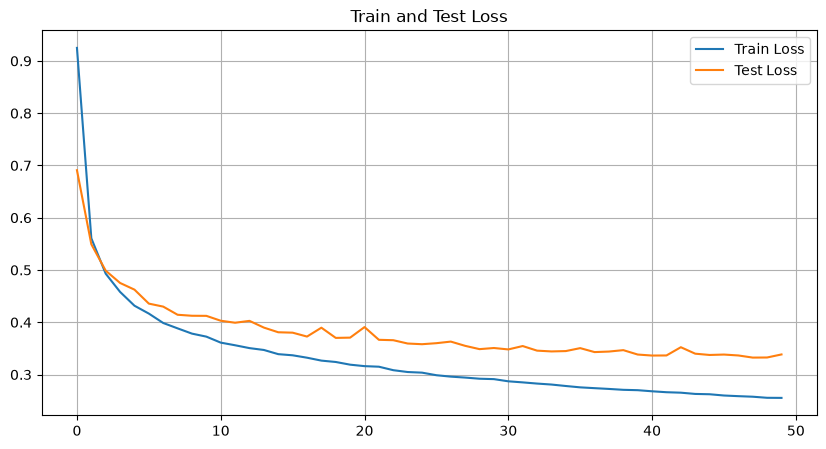

In [22]:
plt.figure(figsize = (10, 5))
plt.plot(train_losses, label = 'Train Loss')
plt.plot(test_losses, label = 'Test Loss')
plt.title('Train and Test Loss')
plt.legend()
plt.grid(True)
plt.show()

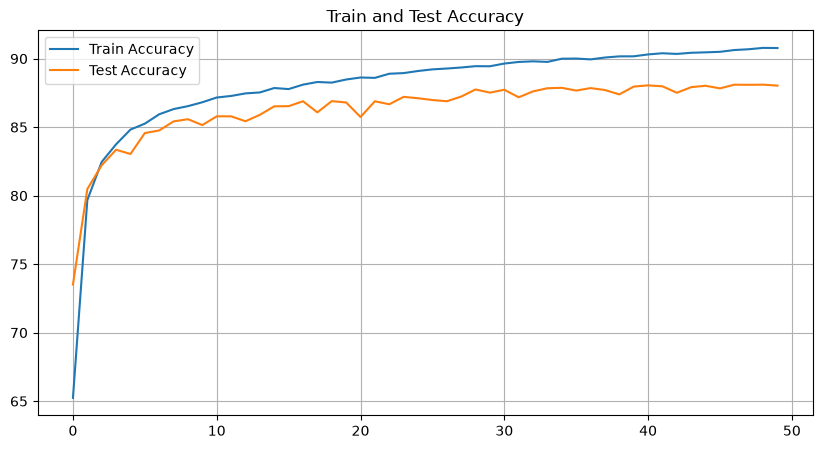

In [23]:
plt.figure(figsize=(10, 5))
plt.plot(train_accuracies, label = 'Train Accuracy')
plt.plot(test_accuracies, label = 'Test Accuracy')
plt.title('Train and Test Accuracy')
plt.grid(True)
plt.legend()
plt.show()